In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from collections import Counter

In [2]:
text = """
machine learning is very interesting
deep learning is a part of machine learning
artificial intelligence is changing the world
machine learning helps computers learn patterns
"""

In [3]:
words = text.lower().split()

print(words)

['machine', 'learning', 'is', 'very', 'interesting', 'deep', 'learning', 'is', 'a', 'part', 'of', 'machine', 'learning', 'artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'machine', 'learning', 'helps', 'computers', 'learn', 'patterns']


In [4]:
##  create vocabulary
vocab = sorted(set(words))

word_to_index = {
    word: i for i, word in enumerate(vocab)
}

index_to_word = {
    i: word for word, i in word_to_index.items()
}

vocab_size = len(vocab)

print("Vocabulary:", vocab)
print("Vocabulary Size:", vocab_size)

Vocabulary: ['a', 'artificial', 'changing', 'computers', 'deep', 'helps', 'intelligence', 'interesting', 'is', 'learn', 'learning', 'machine', 'of', 'part', 'patterns', 'the', 'very', 'world']
Vocabulary Size: 18


In [5]:
#Generate CBOW training data
window_size = 2

data = []

for i in range(window_size, len(words) - window_size):

    context = (
        words[i-window_size:i] +
        words[i+1:i+window_size+1]
    )

    target = words[i]

    data.append((context, target))

print("Training Data:")

for context, target in data[:5]:
    print("Context:", context, "Target:", target)

Training Data:
Context: ['machine', 'learning', 'very', 'interesting'] Target: is
Context: ['learning', 'is', 'interesting', 'deep'] Target: very
Context: ['is', 'very', 'deep', 'learning'] Target: interesting
Context: ['very', 'interesting', 'learning', 'is'] Target: deep
Context: ['interesting', 'deep', 'is', 'a'] Target: learning


In [7]:
#Convert training data into numerical form
X = []
y = []

for context, target in data:

    context_indices = [
        word_to_index[word] for word in context
    ]

    target_index = word_to_index[target]

    X.append(context_indices)
    y.append(target_index)

X = np.array(X)
y = np.array(y)

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (21, 4)
Output Shape: (21,)


In [9]:
#Define the CBOW model
model = keras.Sequential([

    layers.Embedding(
        input_dim=vocab_size,
        output_dim=50
    ),

    layers.Lambda(
        lambda x: tf.reduce_mean(x, axis=1)
    ),

    layers.Dense(
        vocab_size,
        activation='softmax'
    )
])

In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
history = model.fit(
    X,
    y,
    epochs=100,
    batch_size=16,
    verbose=1
)

Epoch 1/100

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.0000e+00 - loss: 2.8895
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0476 - loss: 2.8830
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1429 - loss: 2.8779
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1905 - loss: 2.8731
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3333 - loss: 2.8683
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3810 - loss: 2.8637
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4286 - loss: 2.8590
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4762 - loss: 2.8541
Epoch 9/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4762 - loss: 2.8492
Epoch 10/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4762 - loss: 2.8447
Epoch 11/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4762 - loss: 2.8397
Epoch 12/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5238

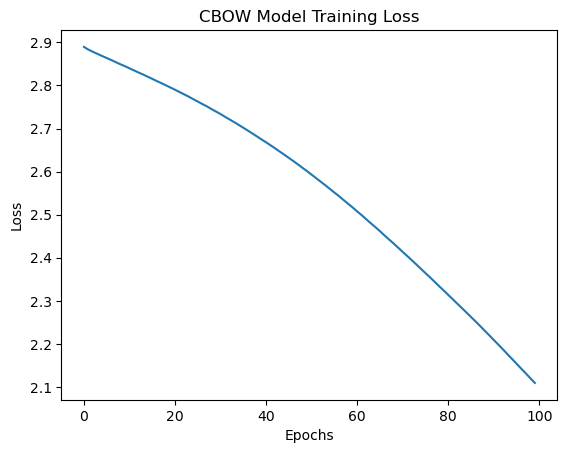

In [12]:
plt.plot(history.history['loss'])

plt.title("CBOW Model Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.show()

In [13]:
context_words = [
    "machine",
    "learning",
    "very",
    "interesting"
]

context_indices = [
    word_to_index[word] for word in context_words
]

input_data = np.array([context_indices])

prediction = model.predict(input_data)

predicted_index = np.argmax(prediction)

predicted_word = index_to_word[predicted_index]

print("Context Words:", context_words)
print("Predicted Target Word:", predicted_word)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Context Words: ['machine', 'learning', 'very', 'interesting']
Predicted Target Word: is
